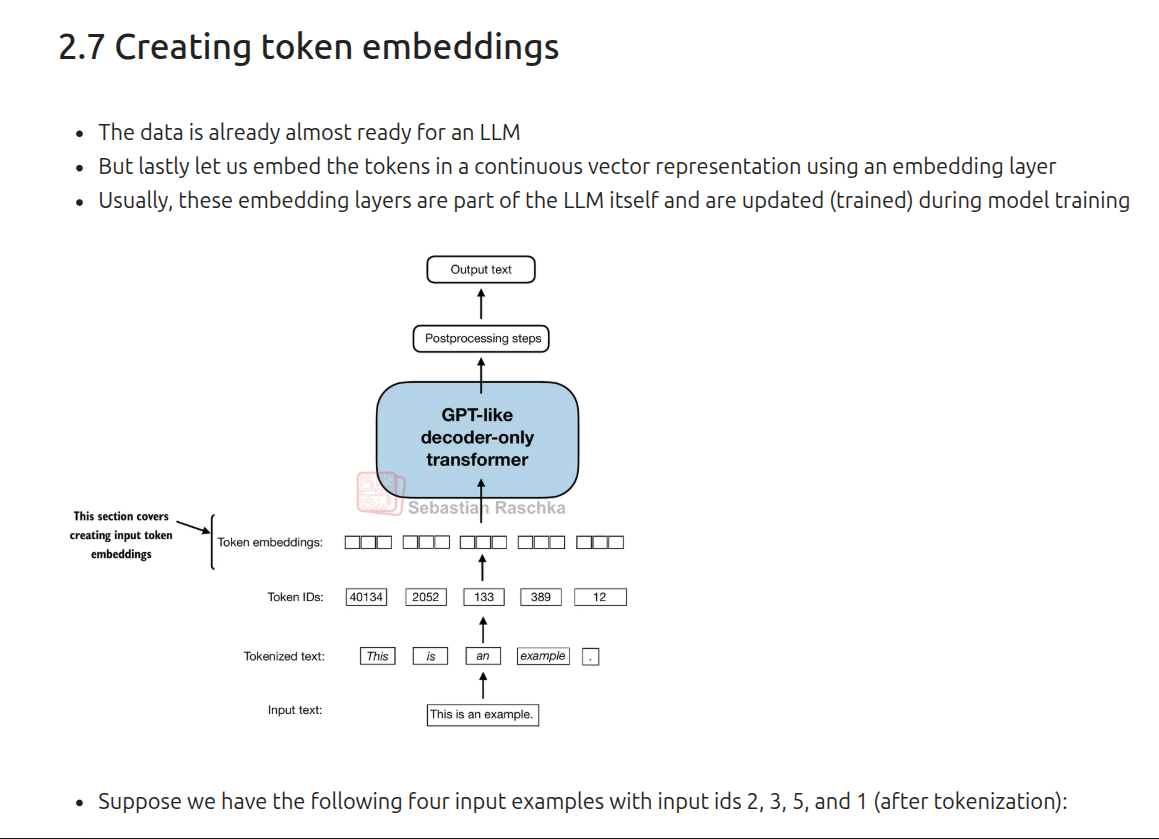

In [1]:
import torch
print("PyTorch version:", torch.__version__)


/home/meet/Desktop/self_project/LLM_From_scratch/.venv/lib/python3.12/site-packages/torch/_subclasses/functional_tensor.py:368: UserWarning: Failed to initialize NumPy: No module named 'numpy' (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:84.)
  cpu = _conversion_method_template(device=torch.device("cpu"))


PyTorch version: 2.14.1+cu130


In [2]:
# Suppose we have the following 3 training examples,
# which may represent token IDs in an LLM context
idx = torch.tensor([2, 3, 1])

# The number of rows in the embedding matrix can be determined by obtaining the largest token ID + 1.
# If the highest token ID is 3, then we want 4 rows, for the possible
print("Maximum index key : " , max(idx))
print("Value at the max index : ",max(idx).item())

num_idx = max(idx) + 1
print("Number of rows in the embedding matrix : ", num_idx)

out_dim = 5  # Let's say we want our embeddings (vector representations of token IDs ) to have 5 dimensions


Maximum index key :  tensor(3)
Value at the max index :  3
Number of rows in the embedding matrix :  tensor(4)


In [3]:
# Let's implement a simple embedding layer:

# We use the random seed for reproducibility since
# weights in the embedding layer are initialized with small random values
torch.manual_seed(123)

embedding_layer = torch.nn.Embedding(num_idx, out_dim)


In [4]:
embedding_layer.weight
# we will get a 4*5 matrix, where each row corresponds to the embedding of a token ID. The rows are initialized with random values.


Parameter containing:
tensor([[ 0.3374, -0.1778, -0.3035, -0.5880,  1.5810],
        [ 1.3010,  1.2753, -0.2010, -0.1606, -0.4015],
        [ 0.6957, -1.8061, -1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096, -0.4076,  0.7953]], requires_grad=True)

In [5]:
# We can then use the embedding layers to obtain the vector representation of a training example with ID 1:
for i in idx:
    print(f"Embedding for index {i.item()}: {embedding_layer(torch.tensor([i]))}") # This will return a tensor of shape (1, out_dim)


Embedding for index 2: tensor([[ 0.6957, -1.8061, -1.1589,  0.3255, -0.6315]],
       grad_fn=<EmbeddingBackward0>)
Embedding for index 3: tensor([[-2.8400, -0.7849, -1.4096, -0.4076,  0.7953]],
       grad_fn=<EmbeddingBackward0>)
Embedding for index 1: tensor([[ 1.3010,  1.2753, -0.2010, -0.1606, -0.4015]],
       grad_fn=<EmbeddingBackward0>)


In [6]:
# POsitional embeddings are used to give the model information about the position of tokens in a sequence. 
# It has the same dimension as the token embeddings, so that the two can be summed.  


### Let's illustrate how the token ID to embedding vector conversion works with a hands-on example. Suppose we have the following four input tokens with IDs 2, 3, 5, and 1:

In [ ]:
input_ids = torch.tensor([2, 3, 5, 1])


### For the sake of simplicity and illustration purposes, suppose we have a small vocabulary of only 6 words (instead of the 50,257 words in the BPE tokenizer vocabulary), and we want to create embeddings of size 3 (in GPT-3, the embedding size is 12,288 dimensions):

In [ ]:
vocab_size = 6
output_dim = 3

torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)


In [ ]:
print(embedding_layer.weight)
# 6*3 matrix, where each row corresponds to the embedding of a token ID. The rows are initialized with random values.


Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)


### We can see that the weight matrix of the embedding layer contains small, random values. These values are optimized during LLM training as part of the LLM optimization itself. 
### Moreover, we can see that the weight matrix has six rows and three columns. There is one row for each of the six possible tokens in the vocabulary. And there is one column for each of the three embedding dimensions.

In [12]:
# After we instantiated the embedding layer, let's now apply it to a token ID to obtain the embedding vector:
print(embedding_layer(torch.tensor([2])))  # This will return a tensor of shape (1, output_dim)


tensor([[ 1.2753, -0.2010, -0.1606]], grad_fn=<EmbeddingBackward0>)


### If we compare the embedding vector for token ID 3 to the previous embedding matrix, we see that it is identical to the 4th row (Python starts with a zero index, so it's the row corresponding to index 3). In other words, the embedding layer is essentially a look-up operation that retrieves rows from the embedding layer's weight matrix via a token ID.

In [13]:
print(embedding_layer(input_ids))


tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


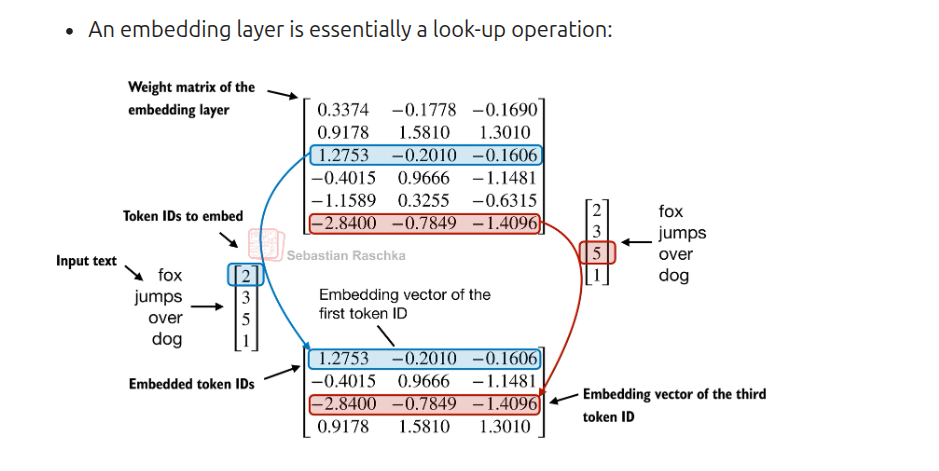

## POSITIONAL EMBEDDINGS (ENCODING WORD POSITIONS)
#### Previously, we focused on very small embedding sizes in this chapter for illustration purposes.
#### We now consider more realistic and useful embedding sizes and encode the input tokens into a           256-dimensional vector representation.
#### This is smaller than what the original GPT-3 model used (in GPT-3, the embedding size is 12,288 dimensions) but still reasonable for experimentation.
#### Furthermore, we assume that the token IDs were created by the BPE tokenizer that we implemented earlier, which has a vocabulary size of 50,257:

### Positional Embedding Intution:
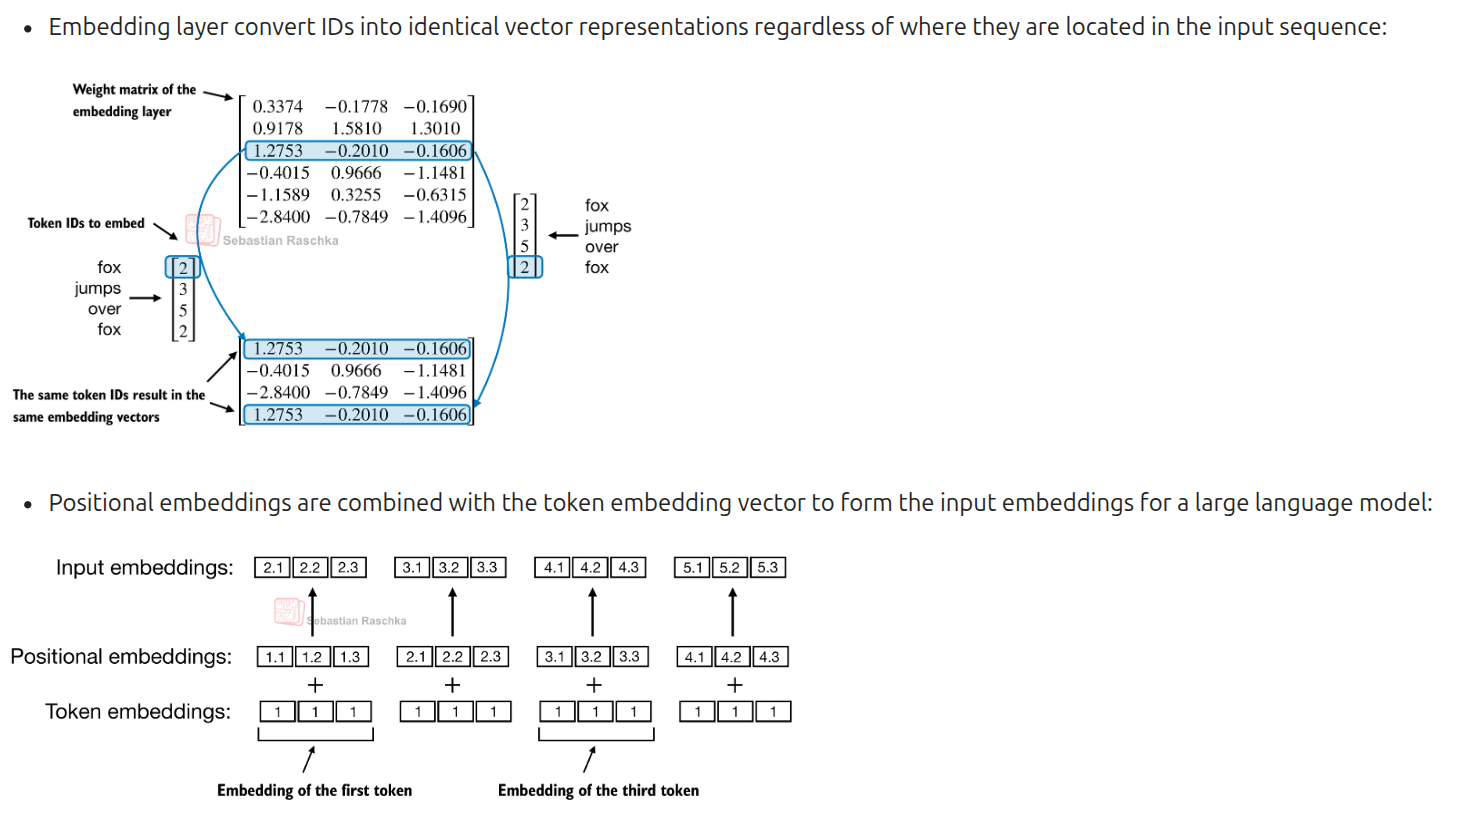

In [ ]:
vocab_size = 50257
output_dim = 256

token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)


### Using the token_embedding_layer above, if we sample data from the data loader, we embed each token in each batch into a 256-dimensional vector. If we have a batch size of 8 with four tokens each, the result will be an 8 x 4 x 256 tensor.
#### 8 - batch of input data
#### 4 - max context length
#### 256 - output dimension on embedding vectors of tokens

In [15]:
from torch.utils.data import Dataset, DataLoader
import tiktoken

class GPTDatasetv1(Dataset):
    def __init__(self, text, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # tokenizing the entire text
        token_ids = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
        assert len(token_ids) > max_length, (
            "Number of tokenized inputs must at least be equal to max_length+1"
        )

        # use a sliding window approach to create input-target pairs and chunking the data into overlapping sequences of length = max_length , if max_length = context_length, then we will have non-overlapping sequences and cover the entire text. If max_length < context_length, then we will have overlapping sequences and cover the entire text.
        
        for i in range(0, len(token_ids) - max_length, stride):
            input_ids = token_ids[i : i + max_length]
            target_ids = token_ids[i + 1 : i + max_length + 1]

            self.input_ids.append(torch.tensor(input_ids, dtype=torch.long))
            self.target_ids.append(torch.tensor(target_ids, dtype=torch.long))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


In [16]:
def create_dataloader_v1(
    text,
    batch_size=4,
    max_length=256,
    stride=128,
    shuffle=True,
    drop_last=True,
    num_workers=0,
):
    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetv1(text, tokenizer, max_length, stride)

    # create DataLoader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
    )

    return dataloader


In [17]:
with open(
    "/home/meet/Desktop/self_project/LLM_From_scratch/the-verdict.txt",
    "r",
    encoding="utf-8",
) as f:
    raw_text = f.read()


In [18]:
# context_length:
max_length = 4

# The stride and context_length are same that signifies that we are not overlapping the sequences and we are covering the entire text. If stride < context_length, then we will have overlapping sequences and cover the entire text.
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length, stride=max_length, shuffle=False
)

data_iter = iter(dataloader)

# get the first batch of inputs and targets
inputs, targets = next(data_iter)


In [ ]:
print("Token IDs:\n", inputs)
print("\nInputs shape:\n", inputs.shape)


Token IDs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs shape:
 torch.Size([8, 4])


#### As we can see, the token ID tensor is 8x4-dimensional, meaning that the data batch consists of 8 text samples with 4 tokens each.

#### Let's now use the embedding layer to embed these token IDs into 256-dimensional vectors:



In [ ]:
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)


torch.Size([8, 4, 256])


#### As we can tell based on the 8x4x256-dimensional tensor output, each token ID is now embedded as a 256-dimensional vector.

#### For a GPT model's absolute Positional embedding approach, we just need to create another embedding layer that has the same dimension as the token_embedding_layer:

In [21]:
context_length = max_length

pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)

pos_embeddings = pos_embedding_layer(torch.arange(max_length))

print(pos_embeddings.shape)


torch.Size([4, 256])


#### As shown in the preceding code example, the input to the pos_embeddings is usually a placeholder vector torch.arange(context_length), which contains a sequence of numbers 0, 1, ..., up to the maximum input length − 1.

#### The context_length is a variable that represents the supported input size of the LLM.

#### Here, we choose it similar to the maximum length of the input text.

#### In practice, input text can be longer than the supported context length, in which case we have to truncate the text.

In [ ]:
input_embeddings = token_embeddings + pos_embeddings
print(input_embeddings.shape)


torch.Size([8, 4, 256])


In [ ]:
print(input_embeddings[0, 0, :])  # embedding of the first token in the first sequence


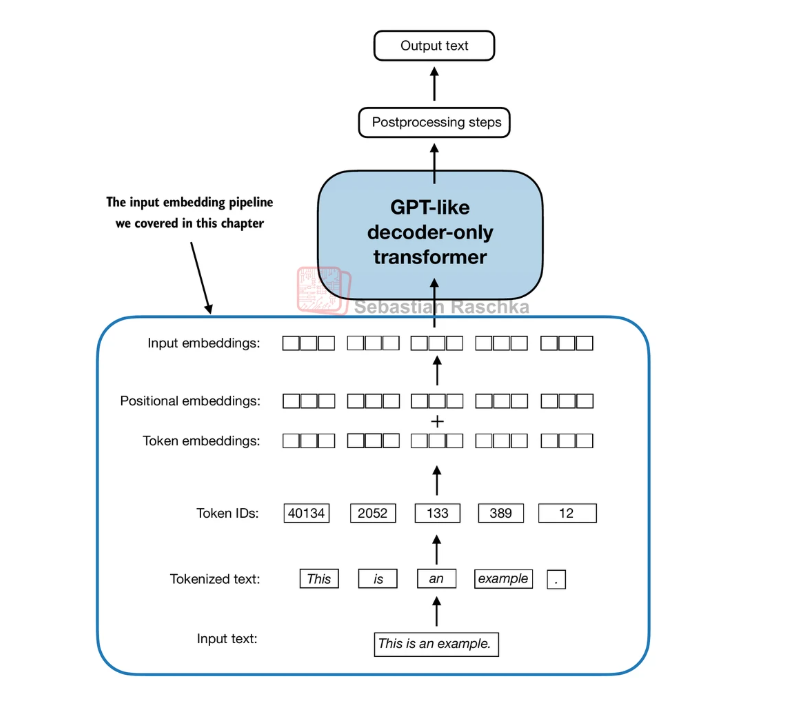